## NAME: MALIK MUHAMMAD ALI HAIDER
## ROLL NUMBER: SP23-BBD-030
## CLASS: BBD 8A (BDS 6)
## SUBJECT: MGT389 NLP FOR BUSINESS / AIC365 NLP
## TOPIC: Lab 07-Tasks
## Submitted to: Sir Zaeem Akbar (zaeemakbar.khan@comsats.edu.pk)

### **Task 1:**: Coarse vs Fine-Grained POS Tags. 
#### Use the sentence: "The quick brown fox jumped over the lazy dogs near the river."

In [50]:
import spacy
from collections import Counter
from spacy import displacy
import matplotlib.pyplot as plt
import json

In [3]:
nlp = spacy.load("en_core_web_sm")

##### a) Load a pretrained spaCy English model, process the sentence, and print each token with its .pos_ tag.

In [4]:
text = "The quick brown fox jumped over the lazy dogs near the river."
doc = nlp(text)

for token in doc:
    print(f"{token.text:<8} {token.pos_}")

The      DET
quick    ADJ
brown    ADJ
fox      NOUN
jumped   VERB
over     ADP
the      DET
lazy     ADJ
dogs     NOUN
near     ADP
the      DET
river    NOUN
.        PUNCT


##### b) Print the same tokens with their .tag_ tags in a second column.

In [30]:
for token in doc:
    print(f"{token.text:<8} {token.tag_}")

Fatima   NNP
quickly  RB
opened   VBD
the      DT
old      JJ
wooden   JJ
door     NN
and      CC
slowly   RB
walked   VBD
into     IN
the      DT
dark     JJ
room     NN
.        .
She      PRP
carefully RB
placed   VBD
a        DT
small    JJ
lamp     NN
on       IN
the      DT
heavy    JJ
table    NN
.        .


##### c) Use spacy.explain() to print a human-readable description for every unique .pos_ and .tag_ value found in the sentence.


In [31]:
unique_pos = sorted({token.pos_ for token in doc})
unique_tags = sorted({token.tag_ for token in doc})

print("Coarse-grained POS values:")
for pos in unique_pos:
    print(f"{pos}: {spacy.explain(pos)}")

print("\nFine-grained POS values:")
for tag in unique_tags:
    print(f"{tag}: {spacy.explain(tag)}")

Coarse-grained POS values:
ADJ: adjective
ADP: adposition
ADV: adverb
CCONJ: coordinating conjunction
DET: determiner
NOUN: noun
PRON: pronoun
PROPN: proper noun
PUNCT: punctuation
VERB: verb

Fine-grained POS values:
.: punctuation mark, sentence closer
CC: conjunction, coordinating
DT: determiner
IN: conjunction, subordinating or preposition
JJ: adjective (English), other noun-modifier (Chinese)
NN: noun, singular or mass
NNP: noun, proper singular
PRP: pronoun, personal
RB: adverb
VBD: verb, past tense


##### d) Write code that finds all tokens where the fine-grained tag differs in meaning from the coarse tag in a notable way (for example, tokens with more than one .tag_ mapping to the same .pos_), and print a count of how many distinct .tag_ values exist for each .pos_.


In [32]:
tag_mapping = {}

for token in doc:
    tag_mapping.setdefault(token.pos_, set()).add(token.tag_)

print("Distinct fine-grained tags for each coarse POS:")
for pos, tags in sorted(tag_mapping.items()):
    print(f"{pos}: {len(tags)}")

print("\nPOS tags with notable fine-grained distinctions:")
for pos, tags in sorted(tag_mapping.items()):
    if len(tags) > 1:
        print(f"{pos}: {sorted(tags)}")

Distinct fine-grained tags for each coarse POS:
ADJ: 1
ADP: 1
ADV: 1
CCONJ: 1
DET: 1
NOUN: 1
PRON: 1
PROPN: 1
PUNCT: 1
VERB: 1

POS tags with notable fine-grained distinctions:


### **Task 2**: Tag Frequency Analysis
#### Use the paragraph: "Ali bought three fresh apples. He carefully washed them and quickly shared them with his friends. Everyone happily enjoyed the sweet fruit."
##### a) Process the paragraph and build a dictionary that counts how many times each .pos_ tag appears.

In [13]:
from collections import Counter
text = (
    "Ali bought three fresh apples. He carefully washed them and quickly "
    "shared them with his friends. Everyone happily enjoyed the sweet fruit."
)
doc = nlp(text)

pos_counts = Counter(token.pos_ for token in doc)
print(pos_counts)

Counter({'PRON': 5, 'VERB': 4, 'NOUN': 3, 'PUNCT': 3, 'ADV': 3, 'ADJ': 2, 'PROPN': 1, 'NUM': 1, 'CCONJ': 1, 'ADP': 1, 'DET': 1})


##### b) Do the same for .tag_ and store the result in a separate dictionary.

In [33]:
tag_counts = Counter(token.tag_ for token in doc)
print(tag_counts)

Counter({'JJ': 5, 'DT': 4, 'NN': 4, 'RB': 3, 'VBD': 3, 'IN': 2, '.': 2, 'NNP': 1, 'CC': 1, 'PRP': 1})


##### c) Display both dictionaries sorted from the most frequent to the least frequent tag.

In [34]:
pos_counts = dict(sorted(
    Counter(token.pos_ for token in doc).items(),
    key=lambda item: (-item[1], item[0])
))

tag_counts = dict(sorted(
    Counter(token.tag_ for token in doc).items(),
    key=lambda item: (-item[1], item[0])
))

print("POS frequencies:")
print(pos_counts)

print("\nTag frequencies:")
print(tag_counts)

POS frequencies:
{'ADJ': 5, 'DET': 4, 'NOUN': 4, 'ADV': 3, 'VERB': 3, 'ADP': 2, 'PUNCT': 2, 'CCONJ': 1, 'PRON': 1, 'PROPN': 1}

Tag frequencies:
{'JJ': 5, 'DT': 4, 'NN': 4, 'RB': 3, 'VBD': 3, '.': 2, 'IN': 2, 'CC': 1, 'NNP': 1, 'PRP': 1}


##### d) Plot a bar chart of the .pos_ frequencies using matplotlib, with labelled axes and a title.

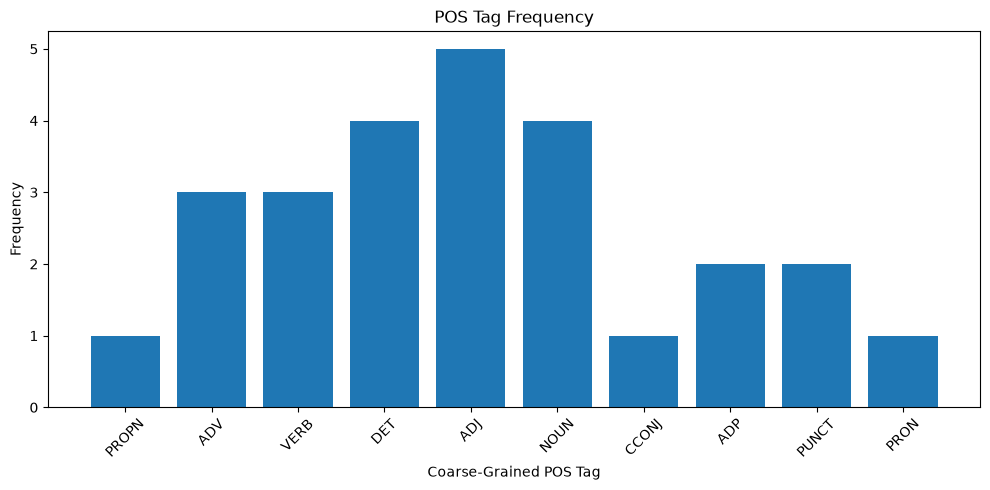

In [35]:
import matplotlib.pyplot as plt
pos_counts = Counter(token.pos_ for token in doc)

plt.figure(figsize=(10, 5))
plt.bar(pos_counts.keys(), pos_counts.values())
plt.xlabel("Coarse-Grained POS Tag")
plt.ylabel("Frequency")
plt.title("POS Tag Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### **Task 3**: Context-Dependent Tagging
#### Use these sentences:
#### 1. "I will book a flight to Lahore."
#### 2. "She read a good book yesterday."
#### 3. "They run every morning."
#### 4. "We watched the run of the play."

##### a) Process all four sentences and print the word "book" with its .pos_ and .tag_ in each sentence where it appears.

In [19]:
sentences = [
    "I will book a flight to Lahore.",
    "She read a good book yesterday.",
    "They run every morning.",
    "We watched the run of the play."
]

for index, sentence in enumerate(sentences, start=1):
    doc = nlp(sentence)
    for token in doc:
        if token.text.lower() == "book":
            print(f"Sentence {index}: {token.text} | POS={token.pos_} | TAG={token.tag_}")

Sentence 1: book | POS=VERB | TAG=VB
Sentence 2: book | POS=NOUN | TAG=NN


##### b) Do the same for the word "run" in the relevant sentences.

In [36]:
for index, sentence in enumerate(sentences, start=1):
    doc = nlp(sentence)
    for token in doc:
        if token.text.lower() == "run":
            print(f"Sentence {index}: {token.text} | POS={token.pos_} | TAG={token.tag_}")

Sentence 3: run | POS=VERB | TAG=VBP
Sentence 4: run | POS=NOUN | TAG=NN


##### c) Write a function compare_word(word, sentences) that takes a word and a list of sentences, and returns a list of tuples (sentence_index, pos_, tag_) for every occurrence of that word.

In [42]:
def compare_word(word, sentences):
    results = []

    for sentence_index, sentence in enumerate(sentences, start=1):
        doc = nlp(sentence)

        for token in doc:
            if token.text.lower() == word.lower():
                results.append((sentence_index, token.pos_, token.tag_))

    return results

##### d) Use your function on two additional ambiguous words of your own choice (such as "light", "play", or "watch") with two sentences each, and print the results.

In [22]:
sentences = [
    "I will book a flight to Lahore.",
    "She read a good book yesterday.",
    "They run every morning.",
    "We watched the run of the play.",
]

light_sentences = [
    "The lamp gives enough light.",
    "The soldiers will light the campfire.",
]

play_sentences = [
    "The children play outside.",
    "We watched the play at the theatre.",
]

print("Light:", compare_word("light", light_sentences))
print("Play:", compare_word("play", play_sentences))

Light: [(1, 'NOUN', 'NN'), (2, 'VERB', 'VB')]
Play: [(1, 'VERB', 'VBP'), (2, 'NOUN', 'NN')]


### **Task 4**: Filtering Noise Tokens
#### Use this messy text:
#### " Hello!!! The price is $45.50 ... (really?)\n\n Is it worth it? xyz123 @@ "
##### a) Process the text and print all tokens with their .pos_ tags, including noise tokens, so the raw output is visible.

In [23]:
messy_text = " Hello!!! The price is $45.50 ... (really?)\n\n Is it worth it? xyz123 @@ "

doc = nlp(messy_text)

for token in doc:
    print(f"{token.text:<12} {token.pos_}")

             SPACE
Hello        INTJ
!            PUNCT
!            PUNCT
!            PUNCT
The          DET
price        NOUN
is           AUX
$            SYM
45.50        NUM
...          PUNCT
(            PUNCT
really       ADV
?            PUNCT
)            PUNCT


           SPACE
Is           AUX
it           PRON
worth        ADJ
it           PRON
?            PUNCT
xyz123       PROPN
@@           PROPN


##### b) Write a list comprehension that removes tokens tagged SPACE, PUNCT, and X, and print the cleaned token list.

In [26]:
cleaned_tokens = [
    token.text
    for token in doc
    if token.pos_ not in {"SPACE", "PUNCT", "X"}
]

print(cleaned_tokens)

['Hello', 'The', 'price', 'is', '$', '45.50', 'really', 'Is', 'it', 'worth', 'it', 'xyz123', '@@']


##### c) Print how many tokens were removed and what percentage of the original tokens they represent.

In [27]:
removed = [token.text for token in doc if token.pos_ in {"SPACE", "PUNCT", "X"}]
original_count = len(doc)
removed_count = len(removed)
removed_percentage = (removed_count / original_count) * 100

print("Removed tokens:", removed)
print("Removed count:", removed_count)
print(f"Removed percentage: {removed_percentage:.2f}%")

Removed tokens: [' ', '!', '!', '!', '...', '(', '?', ')', '\n\n ', '?']
Removed count: 10
Removed percentage: 43.48%


##### d) Write a reusable function clean_pos(text, remove=("SPACE","PUNCT","X")) that returns a list of (token_text, pos_) tuples, and test it with a second text of your own that contains at least five noise tokens.


In [28]:
def clean_pos(text, remove=("SPACE", "PUNCT", "X")):
    doc = nlp(text)
    return [
        (token.text, token.pos_)
        for token in doc
        if token.pos_ not in set(remove)
    ]

second_text = "Wow!!! My_ID=42 @team ... Find #25 in example.txt (now)! xyz ##"

print(clean_pos(second_text))

[('Wow', 'INTJ'), ('My_ID=42', 'PROPN'), ('@team', 'PROPN'), ('Find', 'VERB'), ('#', 'SYM'), ('25', 'NUM'), ('in', 'ADP'), ('now', 'ADV'), ('xyz', 'NOUN'), ('#', 'SYM'), ('#', 'SYM')]


### **Task 5**: Extracting Specific Parts of Speech
#### Use the text: "Fatima quickly opened the old wooden door and slowly walked into the dark room. She carefully placed a small lamp on the heavy table."
##### a) Extract and print all nouns (NOUN and PROPN) from the text.

In [43]:
text = (
    "Fatima quickly opened the old wooden door and slowly walked into "
    "the dark room. She carefully placed a small lamp on the heavy table."
)
doc = nlp(text)

nouns = [
    token.text
    for token in doc
    if token.pos_ in {"NOUN", "PROPN"}
]

print(nouns)

['Fatima', 'door', 'room', 'lamp', 'table']


##### b) Extract and print all verbs, along with their lemmas.

In [44]:
verbs = [
    (token.text, token.lemma_)
    for token in doc
    if token.pos_ == "VERB"
]

print(verbs)

[('opened', 'open'), ('walked', 'walk'), ('placed', 'place')]


##### c) Extract all adjective-noun pairs, where an adjective directly precedes a noun, and print them as strings such as "old door" style pairs (use token indices to check adjacency).

In [45]:
adjective_noun_pairs = [
    f"{doc[index].text} {doc[index + 1].text}"
    for index in range(len(doc) - 1)
    if doc[index].pos_ == "ADJ" and doc[index + 1].pos_ == "NOUN"
]

print(adjective_noun_pairs)

['wooden door', 'dark room', 'small lamp', 'heavy table']


##### d) Print a summary table (using formatted print statements) showing the number of nouns, verbs, adjectives, and adverbs in the text.


In [46]:
counts = {
    "Nouns": sum(token.pos_ in {"NOUN", "PROPN"} for token in doc),
    "Verbs": sum(token.pos_ == "VERB" for token in doc),
    "Adjectives": sum(token.pos_ == "ADJ" for token in doc),
    "Adverbs": sum(token.pos_ == "ADV" for token in doc),
}

print(f"{'Category':<12} {'Count':>5}")
print("-" * 18)

for category, count in counts.items():
    print(f"{category:<12} {count:>5}")

Category     Count
------------------
Nouns            5
Verbs            3
Adjectives       5
Adverbs          3


### **Task 6**: Basic Named Entity Recognition
#### Use the text: "Imran Khan visited Google headquarters in California on March 3, 2019, and discussed a $2 million investment for Pakistan. Later, Microsoft and Amazon announced new offices in Lahore."
##### a) Process the text and print every entity in doc.ents with its text, label, and character start and end positions.


In [47]:
text = (
    "Imran Khan visited Google headquarters in California on March 3, 2019, "
    "and discussed a $2 million investment for Pakistan. Later, Microsoft "
    "and Amazon announced new offices in Lahore."
)
doc = nlp(text)

for entity in doc.ents:
    print(
        f"Text={entity.text:<20} "
        f"Label={entity.label_:<10} "
        f"Start={entity.start_char:<3} "
        f"End={entity.end_char}"
    )

Text=Khan                 Label=PERSON     Start=6   End=10
Text=Google               Label=ORG        Start=19  End=25
Text=California           Label=GPE        Start=42  End=52
Text=March 3, 2019        Label=DATE       Start=56  End=69
Text=$2 million           Label=MONEY      Start=87  End=97
Text=Pakistan             Label=GPE        Start=113 End=121
Text=Microsoft            Label=ORG        Start=130 End=139
Text=Amazon               Label=ORG        Start=144 End=150
Text=Lahore               Label=GPE        Start=176 End=182


##### b) Use spacy.explain() to print the meaning of every unique entity label found.

In [48]:
for label in sorted({entity.label_ for entity in doc.ents}):
    print(f"{label}: {spacy.explain(label)}")

DATE: Absolute or relative dates or periods
GPE: Countries, cities, states
MONEY: Monetary values, including unit
ORG: Companies, agencies, institutions, etc.
PERSON: People, including fictional


##### c) Group the entities by label into a dictionary (label as key, list of entity texts as value) and print it.

In [49]:
entity_groups = {}

for entity in doc.ents:
    entity_groups.setdefault(entity.label_, []).append(entity.text)

print(entity_groups)

{'PERSON': ['Khan'], 'ORG': ['Google', 'Microsoft', 'Amazon'], 'GPE': ['California', 'Pakistan', 'Lahore'], 'DATE': ['March 3, 2019'], 'MONEY': ['$2 million']}


##### d) Count how many entities of each type were found and print the label with the highest count.

In [50]:
label_counts = Counter(entity.label_ for entity in doc.ents)

print(dict(label_counts))

highest_label = max(label_counts, key=label_counts.get)
print(
    f"Highest-count label: {highest_label} "
    f"({label_counts[highest_label]} entities)"
)

{'PERSON': 1, 'ORG': 3, 'GPE': 3, 'DATE': 1, 'MONEY': 1}
Highest-count label: ORG (3 entities)


### **Task 7**: Visualizing Entities with displaCy
#### Use the text: "Apple opened a new store in Karachi in June 2023. Tim Cook said the company plans to invest 500 million dollars across Asia by 2025."
##### a) Use displacy.render() with style="ent" to visualize the entities, and save the output as an HTML file named entities.html.

In [54]:
from spacy import displacy
text = (
    "Apple opened a new store in Karachi in June 2023. "
    "Tim Cook said the company plans to invest 500 million dollars "
    "across Asia by 2025."
)
doc = nlp(text)

html = displacy.render(doc, style="ent", page=True)

html = displacy.render(doc, style="ent", page=True, jupyter=False)

with open("entities.html", "w", encoding="utf-8") as file:
    file.write(html)

##### b) Customize the visualization so that only ORG and GPE entities are highlighted, using the options parameter.

In [56]:
displacy.render(
    doc,
    style="ent",
    jupyter=True,
    options={"ents": ["ORG", "GPE"]},
)

##### c) Customize the colors so that ORG entities appear in orange and GPE entities in light green.

In [57]:
displacy.render(
    doc,
    style="ent",
    jupyter=True,
    options={
        "ents": ["ORG", "GPE"],
        "colors": {
            "ORG": "orange",
            "GPE": "lightgreen",
        },
    },
)

##### d) Render the dependency visualization (style="dep") for the first sentence only, and save it as
dependency.html.

In [59]:
first_sentence = next(doc.sents)
dependency_html = displacy.render(
    first_sentence,
    style="dep",
    page=True,
    jupyter=False,
)

with open("dependency.html", "w", encoding="utf-8") as file:
    file.write(dependency_html)
    
displacy.render(first_sentence, style="dep", jupyter=True)

### **Task 8**: Extending the Model with EntityRuler
#### Use the text: "Dr. Zainab works at LabTech Solutions and uses the Python library NumPy and the framework TensorFlow. Her colleague Abbas prefers PyTorch and Pandas."
##### a) First, process the text with the plain pretrained model and print the entities it detects, noting which of the tech terms (NumPy, TensorFlow, PyTorch, Pandas) are missed or mislabelled.

In [60]:
text = (
    "Dr. Zainab works at LabTech Solutions and uses the Python library "
    "NumPy and the framework TensorFlow. Her colleague Abbas prefers "
    "PyTorch and Pandas."
)
plain_nlp = spacy.load("en_core_web_sm")
doc = plain_nlp(text)

print("Detected entities:")
for entity in doc.ents:
    print(entity.text, entity.label_)

tech_terms = ["NumPy", "TensorFlow", "PyTorch", "Pandas"]

print("\nTech-term status:")
detected_text = {entity.text for entity in doc.ents}

for term in tech_terms:
    if term in detected_text:
        entity = next(entity for entity in doc.ents if entity.text == term)
        print(f"{term}: labelled as {entity.label_}")
    else:
        print(f"{term}: missed")

Detected entities:
Zainab PERSON
LabTech Solutions ORG
Abbas PERSON
PyTorch PERSON
Pandas PERSON

Tech-term status:
NumPy: missed
TensorFlow: missed
PyTorch: labelled as PERSON
Pandas: labelled as PERSON


##### b) Create an EntityRuler and add it to the pipeline with a new label TECH, defining token-based or stringbased patterns for all four tech terms.

In [61]:
ruler_nlp = spacy.load("en_core_web_sm")

ruler = ruler_nlp.add_pipe(
    "entity_ruler",
    before="ner",
    config={"overwrite_ents": True},
)

patterns = [
    {"label": "TECH", "pattern": "NumPy"},
    {"label": "TECH", "pattern": "TensorFlow"},
    {"label": "TECH", "pattern": "PyTorch"},
    {"label": "TECH", "pattern": "Pandas"},
]

ruler.add_patterns(patterns)
ruler_doc = ruler_nlp(text)

print([(entity.text, entity.label_) for entity in ruler_doc.ents])

[('Zainab', 'PERSON'), ('LabTech Solutions', 'ORG'), ('NumPy', 'TECH'), ('TensorFlow', 'TECH'), ('Abbas', 'PERSON'), ('PyTorch', 'TECH'), ('Pandas', 'TECH')]


##### c) Reprocess the text and print the new entity list, confirming that the four terms are now labelled TECH.

In [62]:
tech_nlp = spacy.load("en_core_web_sm")

tech_ruler = tech_nlp.add_pipe(
    "entity_ruler",
    after="ner",
    config={"overwrite_ents": True},
)

tech_ruler.add_patterns([
    {"label": "TECH", "pattern": "NumPy"},
    {"label": "TECH", "pattern": "TensorFlow"},
    {"label": "TECH", "pattern": "PyTorch"},
    {"label": "TECH", "pattern": "Pandas"},
])

doc = tech_nlp(text)

for term in ["NumPy", "TensorFlow", "PyTorch", "Pandas"]:
    entity = next(
        (entity for entity in doc.ents if entity.text == term),
        None,
    )
    print(
        f"{term}: "
        f"{entity.label_ if entity else 'not detected'}"
    )

NumPy: TECH
TensorFlow: TECH
PyTorch: TECH
Pandas: TECH


##### d) Experiment with the overwrite_ents setting and with the position of the ruler (before="ner" versus after="ner"), and print the entities in each case to show how the results differ.

In [63]:
patterns = [
    {"label": "TECH", "pattern": "NumPy"},
    {"label": "TECH", "pattern": "TensorFlow"},
    {"label": "TECH", "pattern": "PyTorch"},
    {"label": "TECH", "pattern": "Pandas"},
]

def test_ruler(position, overwrite_ents):
    experiment_nlp = spacy.load("en_core_web_sm")

    ruler_options = {
        "config": {"overwrite_ents": overwrite_ents},
        position: "ner",
    }

    ruler = experiment_nlp.add_pipe(
        "entity_ruler",
        **ruler_options,
    )
    ruler.add_patterns(patterns)

    doc = experiment_nlp(text)
    entities = [(entity.text, entity.label_) for entity in doc.ents]

    print(
        f"{position=}, overwrite_ents={overwrite_ents}: "
        f"{entities}"
    )

test_ruler("before", False)
test_ruler("before", True)
test_ruler("after", False)
test_ruler("after", True)

position='before', overwrite_ents=False: [('Zainab', 'PERSON'), ('LabTech Solutions', 'ORG'), ('NumPy', 'TECH'), ('TensorFlow', 'TECH'), ('Abbas', 'PERSON'), ('PyTorch', 'TECH'), ('Pandas', 'TECH')]
position='before', overwrite_ents=True: [('Zainab', 'PERSON'), ('LabTech Solutions', 'ORG'), ('NumPy', 'TECH'), ('TensorFlow', 'TECH'), ('Abbas', 'PERSON'), ('PyTorch', 'TECH'), ('Pandas', 'TECH')]
position='after', overwrite_ents=False: [('Zainab', 'PERSON'), ('LabTech Solutions', 'ORG'), ('NumPy', 'TECH'), ('TensorFlow', 'TECH'), ('Abbas', 'PERSON'), ('PyTorch', 'PERSON'), ('Pandas', 'PERSON')]
position='after', overwrite_ents=True: [('Zainab', 'PERSON'), ('LabTech Solutions', 'ORG'), ('NumPy', 'TECH'), ('TensorFlow', 'TECH'), ('Abbas', 'PERSON'), ('PyTorch', 'TECH'), ('Pandas', 'TECH')]


### **Task 9**: Complete Pipeline: From Raw Text to Structured Information
#### Use the text: "Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month. Investors in London and Tokyo reacted quickly, and Tesla shares rose by 4%."
##### a) Write a function that takes raw text and returns a cleaned list of tokens (noise tokens removed) with their .pos_ and .tag_ values.

In [64]:
def clean_text(text, remove=("SPACE", "PUNCT", "X")):
    doc = nlp(text)
    return [
        (token.text, token.pos_, token.tag_)
        for token in doc
        if token.pos_ not in set(remove)
    ]

text = (
    "Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX "
    "will launch a Falcon rocket from Texas next month. Investors "
    "in London and Tokyo reacted quickly, and Tesla shares rose by 4%."
)

cleaned_tokens = clean_text(text)
print(cleaned_tokens)

[('Elon', 'PROPN', 'NNP'), ('Musk', 'PROPN', 'NNP'), ('the', 'DET', 'DT'), ('CEO', 'NOUN', 'NN'), ('of', 'ADP', 'IN'), ('Tesla', 'PROPN', 'NNP'), ('announced', 'VERB', 'VBN'), ('on', 'ADP', 'IN'), ('Tuesday', 'PROPN', 'NNP'), ('that', 'SCONJ', 'IN'), ('SpaceX', 'PROPN', 'NNP'), ('will', 'AUX', 'MD'), ('launch', 'VERB', 'VB'), ('a', 'DET', 'DT'), ('Falcon', 'PROPN', 'NNP'), ('rocket', 'NOUN', 'NN'), ('from', 'ADP', 'IN'), ('Texas', 'PROPN', 'NNP'), ('next', 'ADJ', 'JJ'), ('month', 'NOUN', 'NN'), ('Investors', 'NOUN', 'NNS'), ('in', 'ADP', 'IN'), ('London', 'PROPN', 'NNP'), ('and', 'CCONJ', 'CC'), ('Tokyo', 'PROPN', 'NNP'), ('reacted', 'VERB', 'VBD'), ('quickly', 'ADV', 'RB'), ('and', 'CCONJ', 'CC'), ('Tesla', 'PROPN', 'NNP'), ('shares', 'NOUN', 'NNS'), ('rose', 'VERB', 'VBD'), ('by', 'ADP', 'IN'), ('4', 'NUM', 'CD'), ('%', 'NOUN', 'NN')]


##### b) Add an EntityRuler with a custom label PRODUCT and patterns to capture "Falcon" and "Tesla shares"; then print the final entities, combining the model's and the ruler's results.

In [65]:
pipeline_nlp = spacy.load("en_core_web_sm")

product_ruler = pipeline_nlp.add_pipe(
    "entity_ruler",
    before="ner",
    config={"overwrite_ents": True},
)

product_ruler.add_patterns([
    {"label": "PRODUCT", "pattern": "Falcon"},
    {
        "label": "PRODUCT",
        "pattern": [
            {"TEXT": "Tesla"},
            {"TEXT": "shares"},
        ],
    },
])

final_doc = pipeline_nlp(text)

print([(entity.text, entity.label_) for entity in final_doc.ents])

[('Elon Musk', 'PERSON'), ('Tesla', 'ORG'), ('Tuesday', 'DATE'), ('SpaceX', 'PERSON'), ('Falcon', 'PRODUCT'), ('Texas', 'GPE'), ('next month', 'DATE'), ('London', 'GPE'), ('Tokyo', 'GPE'), ('Tesla shares', 'PRODUCT'), ('4%', 'PERCENT')]


##### c) Build a structured output in Python: a dictionary with keys "tokens", "entities", and "pos_counts", and save it to a JSON file named output.json.

In [67]:
import json
cleaned_tokens = clean_text(text)

final_entities = [
    {
        "text": entity.text,
        "label": entity.label_,
        "start": entity.start_char,
        "end": entity.end_char,
    }
    for entity in final_doc.ents
]

pos_counts = dict(
    Counter(pos for _, pos, _ in cleaned_tokens)
)

output = {
    "tokens": [
        {"text": token_text, "pos": pos, "tag": tag}
        for token_text, pos, tag in cleaned_tokens
    ],
    "entities": final_entities,
    "pos_counts": pos_counts,
}

with open("output.json", "w", encoding="utf-8") as file:
    json.dump(output, file, indent=2, ensure_ascii=False)

print(output)

{'tokens': [{'text': 'Elon', 'pos': 'PROPN', 'tag': 'NNP'}, {'text': 'Musk', 'pos': 'PROPN', 'tag': 'NNP'}, {'text': 'the', 'pos': 'DET', 'tag': 'DT'}, {'text': 'CEO', 'pos': 'NOUN', 'tag': 'NN'}, {'text': 'of', 'pos': 'ADP', 'tag': 'IN'}, {'text': 'Tesla', 'pos': 'PROPN', 'tag': 'NNP'}, {'text': 'announced', 'pos': 'VERB', 'tag': 'VBN'}, {'text': 'on', 'pos': 'ADP', 'tag': 'IN'}, {'text': 'Tuesday', 'pos': 'PROPN', 'tag': 'NNP'}, {'text': 'that', 'pos': 'SCONJ', 'tag': 'IN'}, {'text': 'SpaceX', 'pos': 'PROPN', 'tag': 'NNP'}, {'text': 'will', 'pos': 'AUX', 'tag': 'MD'}, {'text': 'launch', 'pos': 'VERB', 'tag': 'VB'}, {'text': 'a', 'pos': 'DET', 'tag': 'DT'}, {'text': 'Falcon', 'pos': 'PROPN', 'tag': 'NNP'}, {'text': 'rocket', 'pos': 'NOUN', 'tag': 'NN'}, {'text': 'from', 'pos': 'ADP', 'tag': 'IN'}, {'text': 'Texas', 'pos': 'PROPN', 'tag': 'NNP'}, {'text': 'next', 'pos': 'ADJ', 'tag': 'JJ'}, {'text': 'month', 'pos': 'NOUN', 'tag': 'NN'}, {'text': 'Investors', 'pos': 'NOUN', 'tag': 'NNS'

##### d) Use displaCy to render the final entities with custom colors for PERSON, ORG, GPE, and PRODUCT, and write a short loop that prints each entity together with the sentence it came from.

In [68]:
displacy.render(
    final_doc,
    style="ent",
    jupyter=True,
    options={
        "colors": {
            "PERSON": "lightblue",
            "ORG": "orange",
            "GPE": "lightgreen",
            "PRODUCT": "violet",
        },
    },
)

for entity in final_doc.ents:
    print(
        f"Entity: {entity.text:<12} "
        f"Label: {entity.label_:<8} "
        f"Sentence: {entity.sent.text}"
    )

Entity: Elon Musk    Label: PERSON   Sentence: Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
Entity: Tesla        Label: ORG      Sentence: Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
Entity: Tuesday      Label: DATE     Sentence: Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
Entity: SpaceX       Label: PERSON   Sentence: Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
Entity: Falcon       Label: PRODUCT  Sentence: Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
Entity: Texas        Label: GPE      Sentence: Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
Entity: next month   Label: DATE     Sen